In [8]:
import json
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

# Cargar los datos de la visualización anterior
html = Path("01-profiles.html").read_text(encoding="utf-8")

data = json.JSONDecoder().raw_decode(
    html.split("const D=", 1)[1].lstrip()
)[0]

X = np.array(data["x"])
species = np.array(data["species"])

features = [
    "Longitud del sépalo",
    "Anchura del sépalo",
    "Longitud del pétalo",
    "Anchura del pétalo"
]

df = pd.DataFrame(X, columns=features)

df["Especie real"] = species
df["Cluster estandarizado"] = data["models"]["scaled"]["labels"]
df["Cluster sin estandarizar"] = data["models"]["raw"]["labels"]

df.head()

,Longitud del sépalo,Anchura del sépalo,Longitud del pétalo,Anchura del pétalo,Especie real,Cluster estandarizado,Cluster sin estandarizar
0,5.1,3.5,1.4,0.2,0,0,0
1,4.9,3.0,1.4,0.2,0,0,0
2,4.7,3.2,1.3,0.2,0,0,0
3,4.6,3.1,1.5,0.2,0,0,0
4,5.0,3.6,1.4,0.2,0,0,0


In [9]:
depths = [1, 2, 3, 4, 5, None]

models = {}
results = []

for mode in ["scaled", "raw"]:

    y = np.array(data["models"][mode]["labels"])

    train, test = train_test_split(
        np.arange(len(X)),
        test_size=0.30,
        random_state=42,
        stratify=y
    )

    models[mode] = {
        "labels": y,
        "train": train,
        "test": test,
        "trees": {}
    }

    for depth in depths:

        tree = DecisionTreeClassifier(
            max_depth=depth,
            criterion="gini",
            random_state=42
        )

        tree.fit(X[train], y[train])

        models[mode]["trees"][depth] = tree

        results.append({
            "Modelo": mode,
            "Profundidad máxima": depth,
            "Profundidad real": tree.get_depth(),
            "Hojas": tree.get_n_leaves(),
            "Fidelidad entrenamiento": tree.score(
                X[train], y[train]
            ),
            "Fidelidad validación": tree.score(
                X[test], y[test]
            )
        })

results_df = pd.DataFrame(results)

results_df

,Modelo,Profundidad máxima,Profundidad real,Hojas,Fidelidad entrenamiento,Fidelidad validación
0,scaled,1.0,1,2,0.685714,0.688889
1,scaled,2.0,2,3,0.914286,0.955556
2,scaled,3.0,3,5,0.980952,0.977778
3,scaled,4.0,4,6,0.980952,0.977778
4,scaled,5.0,5,8,0.990476,0.977778
5,scaled,NaN,7,10,1.000000,0.977778
6,raw,1.0,1,2,0.742857,0.755556
7,raw,2.0,2,3,0.990476,0.933333
8,raw,3.0,3,4,0.990476,0.933333
9,raw,4.0,4,5,1.000000,0.955556


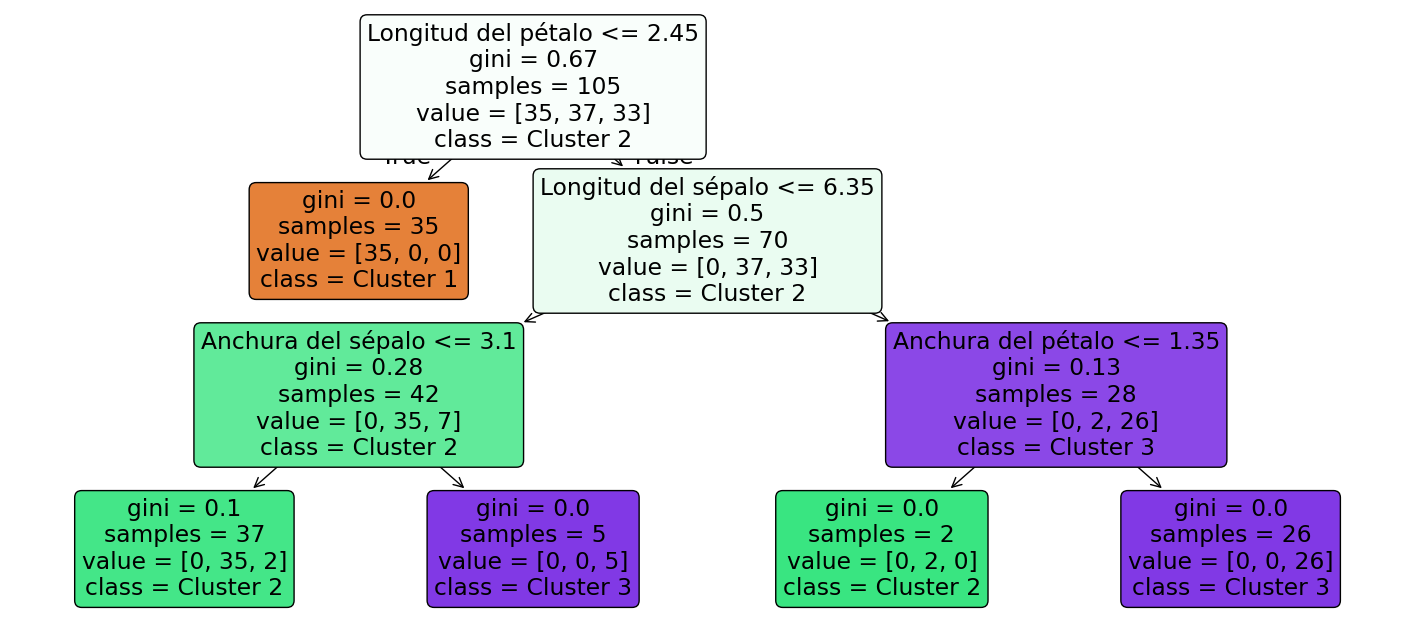

In [10]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

tree = models["scaled"]["trees"][3]

plt.figure(figsize=(18, 8))

plot_tree(
    tree,
    feature_names=features,
    class_names=[
        f"Cluster {c + 1}"
        for c in tree.classes_
    ],
    filled=True,
    rounded=True,
    precision=2
)

plt.show()

In [11]:
def export_tree(tree, X, y, train, test):

    t = tree.tree_
    predictions = tree.predict(X)

    nodes = []

    for i in range(t.node_count):

        is_leaf = t.children_left[i] == -1

        nodes.append({
            "id": i,
            "left": None if is_leaf else int(
                t.children_left[i]
            ),
            "right": None if is_leaf else int(
                t.children_right[i]
            ),
            "feature": None if is_leaf else int(
                t.feature[i]
            ),
            "threshold": None if is_leaf else float(
                t.threshold[i]
            ),
            "samples": int(t.n_node_samples[i]),
            "impurity": float(t.impurity[i]),
            "distribution": t.value[i][0].tolist(),
            "prediction": int(
                tree.classes_[np.argmax(t.value[i][0])]
            )
        })

    return {
        "max_depth": tree.max_depth,
        "actual_depth": tree.get_depth(),
        "leaves": tree.get_n_leaves(),
        "classes": tree.classes_.tolist(),
        "nodes": nodes,
        "predictions": predictions.tolist(),
        "leaf_ids": tree.apply(X).tolist(),
        "decision_paths": [
            tree.decision_path(X[i:i+1]).indices.tolist()
            for i in range(len(X))
        ],
        "fidelity": {
            "train": float(tree.score(X[train], y[train])),
            "validation": float(tree.score(X[test], y[test])),
            "all": float(tree.score(X, y))
        },
        "validation_confusion": confusion_matrix(
            y[test],
            predictions[test],
            labels=[0, 1, 2]
        ).tolist()
    }

In [13]:
export_data = {
    "features": features,
    "units": "cm",
    "observations": X.tolist(),
    "species": species.tolist(),
    "species_names": [
        "Setosa",
        "Versicolor",
        "Virginica"
    ],
    "random_state": 42,
    "models": {}
}

for mode, model in models.items():

    y = model["labels"]
    train = model["train"]
    test = model["test"]

    majority_species = [
        int(np.bincount(
            species[y == k], minlength=3
        ).argmax())
        for k in range(3)
    ]

    export_data["models"][mode] = {
        "labels": y.tolist(),
        "majority_species": majority_species,
        "train_indices": train.tolist(),
        "test_indices": test.tolist(),
        "trees": [
            export_tree(tree, X, y, train, test)
            for tree in model["trees"].values()
        ]
    }

def numpy_converter(obj):
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.bool_):
        return bool(obj)

    raise TypeError(f"Tipo no serializable: {type(obj)}")


with open("iris_rules.json", "w", encoding="utf-8") as f:
    json.dump(
        export_data,
        f,
        ensure_ascii=False,
        indent=2,
        default=numpy_converter
    )

print("Archivo iris_rules.json generado correctamente")

print("Archivo iris_rules.json generado correctamente")

Archivo iris_rules.json generado correctamente
Archivo iris_rules.json generado correctamente


In [15]:
import json
import pandas as pd
import matplotlib.pyplot as plt

# Cargar los datos exportados
with open("iris_rules.json", encoding="utf-8") as f:
    data = json.load(f)

results = []

for mode, model in data["models"].items():
    for tree in model["trees"]:

        results.append({
            "Modelo": mode,
            "Profundidad máxima": (
                tree["max_depth"]
                if tree["max_depth"] is not None
                else "Sin límite"
            ),
            "Profundidad real": tree["actual_depth"],
            "Hojas": tree["leaves"],
            "Fidelidad entrenamiento": tree["fidelity"]["train"] * 100,
            "Fidelidad validación": tree["fidelity"]["validation"] * 100,
            "Fidelidad total": tree["fidelity"]["all"] * 100
        })

df_results = pd.DataFrame(results)

df_results.round(2)

,Modelo,Profundidad máxima,Profundidad real,Hojas,Fidelidad entrenamiento,Fidelidad validación,Fidelidad total
0,scaled,1,1,2,68.57,68.89,68.67
1,scaled,2,2,3,91.43,95.56,92.67
2,scaled,3,3,5,98.10,97.78,98.00
3,scaled,4,4,6,98.10,97.78,98.00
4,scaled,5,5,8,99.05,97.78,98.67
5,scaled,Sin límite,7,10,100.00,97.78,99.33
6,raw,1,1,2,74.29,75.56,74.67
7,raw,2,2,3,99.05,93.33,97.33
8,raw,3,3,4,99.05,93.33,97.33
9,raw,4,4,5,100.00,95.56,98.67


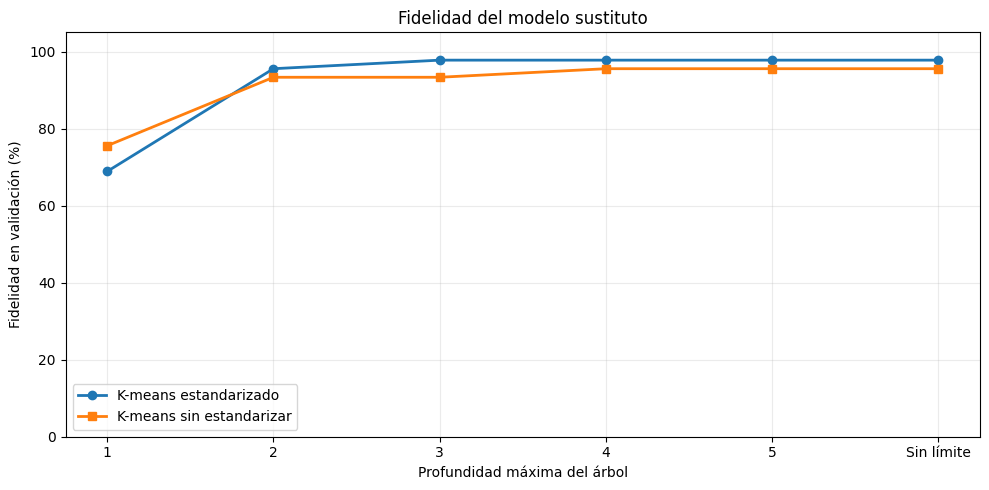

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    range(len(tabla)),
    tabla["K-means estandarizado"],
    marker="o",
    linewidth=2,
    label="K-means estandarizado"
)

ax.plot(
    range(len(tabla)),
    tabla["K-means sin estandarizar"],
    marker="s",
    linewidth=2,
    label="K-means sin estandarizar"
)

ax.set_xticks(range(len(tabla)))
ax.set_xticklabels(tabla.index)

ax.set_xlabel("Profundidad máxima del árbol")
ax.set_ylabel("Fidelidad en validación (%)")
ax.set_title("Fidelidad del modelo sustituto")

ax.set_ylim(0, 105)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()